In [1]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.model_selection import GridSearchCV
from sklearn.metrics import confusion_matrix, accuracy_score, classification_report, recall_score, precision_score

from regulation import X_train
from types_pandas import DataFrame


In [2]:
df = pd.read_csv('data.csv')
df

,User ID,Gender,Age,EstimatedSalary,Purchased
0,15624510,Male,19,19000,0
1,15810944,Male,35,20000,0
2,15668575,Female,26,43000,0
3,15603246,Female,27,57000,0
4,15804002,Male,19,76000,0
...,...,...,...,...,...
395,15691863,Female,46,41000,1
396,15706071,Male,51,23000,1
397,15654296,Female,50,20000,1
398,15755018,Male,36,33000,0


In [3]:
print("Количество строк: ", df.shape[0], '')

Количество строк:  400 


In [4]:
print("Количество столбцов: ", df.shape[1], '')

Количество столбцов:  5 


In [5]:
df.columns

Index(['User ID', 'Gender', 'Age', 'EstimatedSalary', 'Purchased'], dtype='str')

In [6]:
df.head().style.background_gradient(cmap='coolwarm')

,User ID,Gender,Age,EstimatedSalary,Purchased
0,15624510,Male,19,19000,0
1,15810944,Male,35,20000,0
2,15668575,Female,26,43000,0
3,15603246,Female,27,57000,0
4,15804002,Male,19,76000,0


In [7]:
df.describe().T.style.background_gradient(cmap='coolwarm')

,count,mean,std,min,25%,50%,75%,max
User ID,400.000000,15691539.757500,71658.321581,15566689.000000,15626763.750000,15694341.500000,15750363.000000,15815236.000000
Age,400.000000,37.655000,10.482877,18.000000,29.750000,37.000000,46.000000,60.000000
EstimatedSalary,400.000000,69742.500000,34096.960282,15000.000000,43000.000000,70000.000000,88000.000000,150000.000000
Purchased,400.000000,0.357500,0.479864,0.000000,0.000000,0.000000,1.000000,1.000000


In [8]:
df.duplicated().sum()

np.int64(0)

In [9]:
df.isnull().sum()

User ID            0
Gender             0
Age                0
EstimatedSalary    0
Purchased          0
dtype: int64

In [10]:
plt.figure(figsize=(10, 5))
mask = np.triu(np.ones_like(df.corr(), dtype=bool))
sns.heatmap(df.corr, mask=mask, cmap='coolwarm', annot=True)

ValueError: could not convert string to float: 'Male'

<Figure size 1000x500 with 0 Axes>

In [ ]:
correlation = pd.DataFrame(df.corr().Purchased())

In [11]:
df.drop('User ID', axis = 1, inplace = True)

In [12]:
df['Purchased'].value_counts()

Purchased
0    257
1    143
Name: count, dtype: int64

C:\Users\Riba\AppData\Local\Temp\ipykernel_2668\1437240930.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(x='Purchased', data=df, palette='Dark2')


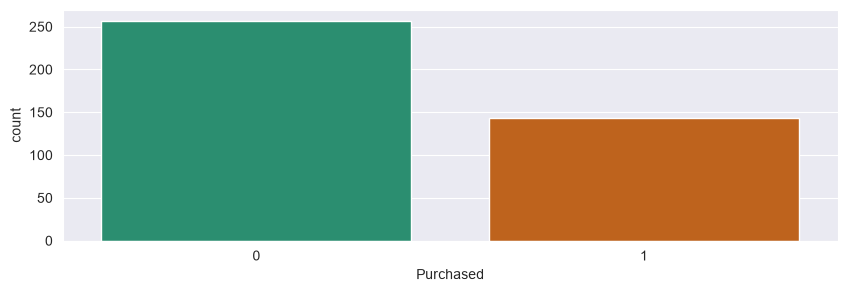

In [13]:
plt.figure(figsize=(10, 3))
sns.countplot(x='Purchased', data=df, palette='Dark2')
plt.show()

In [ ]:
plt.figure(figsize=(10, 3))
sns.countplot(x='Purchased', data=df, palette='Dark2')
plt.show()

<Axes: xlabel='Age', ylabel='Count'>

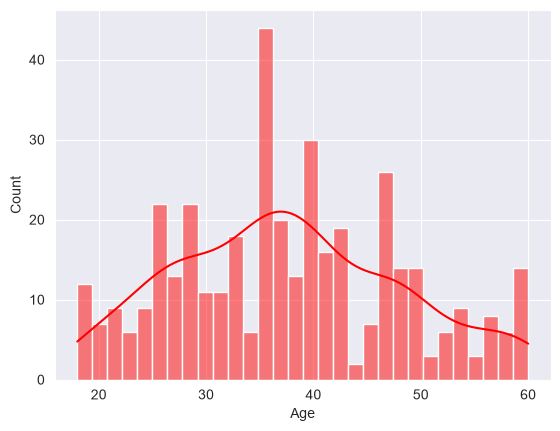

In [14]:
sns.histplot(df['Age'], kde=True, bins=30, color='red')

In [ ]:
df = pd.get_dummies()

In [ ]:
X = df.drop('Purchased', axis=1)
y = df['Purchased']

In [ ]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, random_state=0)

In [ ]:
cols = X_train.columns

In [ ]:
sc = StandardScaler()
X_train = sc.fit_transform(X_train)
X_test = sc.transform(X_test)
X_train = DataFrame(X_train, columns=cols)
X_test = DataFrame(X_test, columns=cols)

In [ ]:
classifierKNN = KNeighborsClassifier(n_neighbors=5)
classifierKNN.fit(X_train, y_train)